In [1]:
push!(LOAD_PATH,"./")
push!(LOAD_PATH,"julia/")
include("model.jl")
using Plots
using DataFrames
using CSV

function parameters(row)
    Dict("alpha" => row["alpha"], "beta" => row["beta"], "gamma" => 0, "delta" => 1e-6, "lambda" => row["lambda"], "b" => row["b"], "c" => row["c"], "n" => row["n"])
end
function strategy(row)
    Strategy(row["piAA"],row["piAB"],row["piBA"],row["piBB"],row["thetaAA"],row["thetaAB"],row["thetaBA"],row["thetaBB"],0.0,0.0)
end

strategy (generic function with 1 method)

In [2]:
d1 = CSV.read("results/E1new_results.csv.gz",DataFrame)
d2 = d1[(d1.n .== 5), :]


Row,alpha,beta,gamma,delta,b,c,lambda,n,replicate,mutationType,nMutants,mutationSize,mutationProbability,piAA,piAB,piBA,piBB,thetaAA,thetaAB,thetaBA,thetaBB,rhoA,rhoB,fitness
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64,String7,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.1,0.0,0.0,1.0e-6,0.615572,1.0,1.0,5,6,default,100000,0.3,0.1,0.0,1.0,0.0,1.0,0.0,0.0,0.440125,0.145532,0.0,0.0,-1.9221e-6
2,0.199526,4.0,0.0,1.0e-6,0.615572,1.0,1.0,5,1,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.973427,1.0,0.0,1.0,0.0,0.0,0.0111631
3,1.05925,4.0,0.0,1.0e-6,2.46229,1.0,1.0,5,1,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.843033,0.0,0.0520245,0.0,0.0,0.0,0.791392
4,5.95662,0.0,0.0,1.0e-6,6.49802,1.0,1.0,5,10,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.547615,0.0,0.418124,0.0494667,0.0,0.0,2.77783
5,0.891251,4.0,0.0,1.0e-6,0.217638,1.0,1.0,5,2,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.00373023
6,5.30884,0.0,0.0,1.0e-6,1.1487,1.0,1.0,5,1,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.0,0.919278,0.0,0.334581,0.0,0.0,0.427356
7,0.1,0.0,0.0,1.0e-6,0.757858,1.0,1.0,5,3,default,100000,0.3,0.1,0.0,1.0,0.0,1.0,0.397386,0.095396,0.115854,0.0880032,0.0,0.0,-1.21068e-6
8,1.77828,0.0,0.0,1.0e-6,2.63902,1.0,1.0,5,1,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.556163,0.222932,0.0,0.38551,0.0,0.0,0.837937
9,11.2202,4.0,0.0,1.0e-6,0.406126,1.0,1.0,5,1,default,100000,0.3,0.1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.152346


In [3]:
results = [solveModel(parameters(row),strategy(row)) for row in eachrow(d2)]


147620-element Vector{@NamedTuple{uA::Vector{Float64}, uB::Vector{Float64}, meanA::Float64, meanB::Float64, I::Vector{Float64}}}:
 (uA = [0.999950001999931, 4.999700012955735e-5, 9.99929661223651e-10, 9.833725928828575e-15, -8.18042220357121e-17, -3.2982256140172445e-17], uB = [0.9999500019999309, 4.999700012961882e-5, 9.999296662646203e-10, 9.835502572127729e-15, -8.207885127985308e-17, -3.293911589913823e-17], meanA = 9.999800003577768e-6, meanB = 9.999800003592968e-6, I = [0.0, 1.0])
 (uA = [0.7346555692413931, 0.13986300658334572, 0.07266251451385296, 0.036463902745189784, 0.013640535289617249, 0.0027144716266012145], uB = [0.9081223622175288, 0.0413073481907432, 0.028068633955794713, 0.015418709177537975, 0.005912926350253613, 0.0011700201081416895], meanA = 0.09254284862761922, meanB = 0.03464050991533389, I = [0.0, 1.0])
 (uA = [0.002981625806948381, 0.006305214679516772, 0.01577301987234107, 0.04154700791255982, 0.11576897962084885, 0.817624152107785], uB = [0.02187547645098989

In [4]:
d2.meanA = [clamp(x.meanA,0,1) for x in results]
d2.meanB = [clamp(x.meanB,0,1) for x in results]
for i in 1:6
    d2[!, "uA_" * string(i-1)] = [clamp(x.uA[i],0,1) for x in results]
    d2[!, "uB_" * string(i-1)] = [clamp(x.uB[i],0,1) for x in results]
end
d2.ps = [1 - 0.5*(1/25)*sum(x.uA .* (0:5) .* reverse(0:5)) - 0.5*(1/25)*sum(x.uB .* (0:5) .* reverse(0:5)) for x in results] # probability two individuals are in the same state at the same time
d2.pt = [1 - 0.25 * x.meanA * (1-x.meanA) - 0.25 * x.meanB * (1-x.meanB) - 0.5 * x.meanA * (1-x.meanB) - 0.5 * (1-x.meanA) * x.meanB for x in results] # probability two individuals are in the same state at different times
d2.ph = [0.5*(x.uA[1] + x.uA[6]) + 0.5*(x.uB[1] + x.uB[6]) for x in results]
#d2.ps = [0.5 * sum(x.uA .* x.uA) + 0.5 * sum(x.uB .* x.uB) for x in results]
#d2.pt = [sum((0.5 * x.uA + 0.5 * x.uB) .* (0.5 * x.uA + 0.5 * x.uB)) for x in results]
CSV.write("results/E1_processed.csv", d2)


"results/E1_processed.csv"

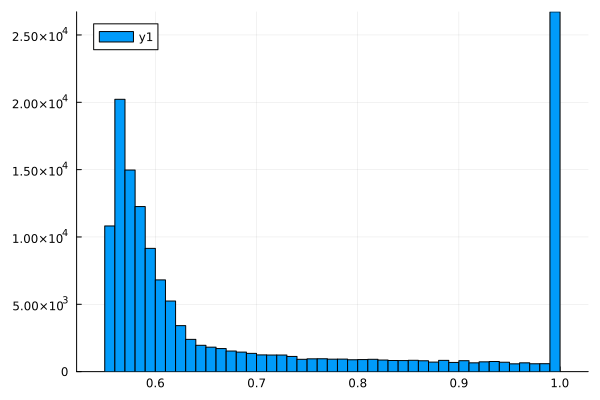

In [32]:
histogram(d2.pt)

In [22]:
z = 0.5*results[1].uA + 0.5*results[1].uB
sum(z.*z)

0.2864283448834236

In [9]:
first(d2,5)

Row,alpha,beta,gamma,b,c,lambda,n,replicate,nMutants,mutationSize,mutationProbability,piAA,piAB,piBA,piBB,thetaAA,thetaAB,thetaBA,thetaBB,fitness,meanA,meanB,uA_0,uA_1,uA_2,uA_3,uA_4,uA_5
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,5.7,0.0,1.0e-6,0.307786,1.0,1.0,5,4,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.384514,0.494467,0.0,0.0,0.0689718,0.87013,0.87013,0.0240088,0.033794,0.0463034,0.067588,0.120045,0.708261
2,5.25,0.0,1.0e-6,4.59479,1.0,1.0,5,4,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.149816,0.629728,0.0,0.437259,1.91155,0.862069,0.862069,0.0253409,0.0359956,0.0494269,0.0719913,0.126705,0.69054
3,3.9,1.0,1.0e-6,0.287175,1.0,1.0,5,1,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0410179,0.807575,0.807575,0.0352958,0.0528128,0.0743681,0.103702,0.143887,0.589935
4,5.6,0.0,1.0e-6,1.1487,1.0,1.0,5,5,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.432987,0.868421,0.868421,0.0242931,0.0342595,0.0469625,0.0685191,0.121466,0.7045
5,1.95,1.0,1.0e-6,4.28709,1.0,1.0,5,1,10000,0.3,0.1,1.0,0.0,1.0,0.0,1.0,0.0,0.998339,0.0,1.64355,1.0,1.0,0.0,-1.50376e-17,-2.01784e-17,1.14921e-12,1.69491e-6,0.999998


In [ ]:

keys = string.(d2.alpha, "_", d2.b)
d2.unique_id = indexin(keys, unique(keys))
sort!(d2, [:unique_id, :fitness], rev=[false, true])
d2 = unique(d2, :unique_id)

In [63]:
strategy_colors = Dict(
    "other" => missing,
    "always active" => "#666666",
    "always inactive" => "#cccccc",
    "naive flexible" => "#aaeeff",
    "delay activation" => "#b380ff",
    "delay inactivation" => "#ff8080",
    "anticipate activation" => "#ffe680",
    "anticipate inactivation" => "#deaa87",
    "none" => "#eeeeee",
    "positive_feedback_active" => "#ffa500",
    "negative_feedback_active" => "coral",
    "positive_feedback_inactive" => "cornflowerblue",
    "negative_feedback_inactive" => "purple",
    "positive_feedback_both" => "#91ee92",
    "positive_feedback_both_extra_activation" => "#eeee00",
    "positive_feedback_both_extra_inactivation" => "#44ce82",
    "activation" => "#8c5f09",
    "inactivation" => "#551a8b"
)

Dict{String, Union{Missing, String}} with 18 entries:
  "always active"                             => "#666666"
  "positive_feedback_both_extra_inactivation" => "#44ce82"
  "positive_feedback_active"                  => "#ffa500"
  "positive_feedback_inactive"                => "cornflowerblue"
  "negative_feedback_active"                  => "coral"
  "anticipate activation"                     => "#ffe680"
  "inactivation"                              => "#551a8b"
  "activation"                                => "#8c5f09"
  "delay inactivation"                        => "#ff8080"
  "naive flexible"                            => "#aaeeff"
  "anticipate inactivation"                   => "#deaa87"
  "always inactive"                           => "#cccccc"
  "positive_feedback_both_extra_activation"   => "#eeee00"
  "positive_feedback_both"                    => "#91ee92"
  "none"                                      => "#eeeeee"
  "negative_feedback_inactive"                => "purple

In [ ]:
d1.strategy_theta = [
    call_strategy_theta(row.thetaAA, row.thetaAB, row.thetaBA, row.thetaBB)
    for row in eachrow(d1)
]

d2 = d1[(d1.beta .== 10) .& (d1.n .== 5), :]
keys = string.(d2.alpha, "_", d2.b)
d2.unique_id = indexin(keys, unique(keys))
sort!(d2, [:unique_id, :fitness], rev=[false, true])
d2 = unique(d2, :unique_id)


Row,alpha,beta,gamma,b,c,lambda,n,replicate,nMutants,mutationSize,mutationProbability,piAA,piAB,piBA,piBB,thetaAA,thetaAB,thetaBA,thetaBB,fitness,strategy_theta,unique_id
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,String,Union…
1,0.05,10.0,1.0e-6,2.0,1.0,1.0,5,2,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.728788,0.0,1.0,1.0,0.504188,positive_feedback_both_extra_activation,5815
2,0.1,10.0,1.0e-6,2.0,1.0,1.0,5,2,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.730438,0.0,1.0,1.0,0.508207,positive_feedback_both_extra_activation,5593
3,0.15,10.0,1.0e-6,2.0,1.0,1.0,5,4,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.732584,0.0,1.0,1.0,0.512074,positive_feedback_both_extra_activation,5647
4,0.2,10.0,1.0e-6,2.0,1.0,1.0,5,5,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.733873,0.0,1.0,1.0,0.515803,positive_feedback_both_extra_activation,5115
5,0.25,10.0,1.0e-6,2.0,1.0,1.0,5,2,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.735654,0.0,1.0,1.0,0.519407,positive_feedback_both_extra_activation,6697
6,0.3,10.0,1.0e-6,2.0,1.0,1.0,5,1,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.736644,0.0,1.0,1.0,0.522896,positive_feedback_both_extra_activation,3601
7,0.35,10.0,1.0e-6,2.0,1.0,1.0,5,1,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.750722,0.0,0.954065,1.0,0.52628,positive_feedback_both_extra_activation,2479
8,0.4,10.0,1.0e-6,2.0,1.0,1.0,5,1,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.760266,0.0,0.914746,1.0,0.529586,positive_feedback_both_extra_activation,6797
9,0.45,10.0,1.0e-6,2.0,1.0,1.0,5,4,10000,0.3,0.1,1.0,0.0,0.0,1.0,0.784957,0.0,0.834958,1.0,0.532834,positive_feedback_both_extra_activation,4192


In [65]:
function parameters(row)
    Dict("alpha" => row["alpha"], "beta" => row["beta"], "gamma" => 0, "delta" => 1e-6, "lambda" => row["lambda"], "b" => row["b"], "c" => row["c"], "n" => row["n"])
end
function strategy(row)
    Strategy(row["piAA"],row["piAB"],row["piBA"],row["piBB"],row["thetaAA"],row["thetaAB"],row["thetaBA"],row["thetaBB"],0.0,0.0)
end

strategy (generic function with 1 method)

In [82]:
d = d2[d2.b .== 2, :]
sort!(d, :alpha, rev=false)
results = [solveModel(parameters(row),strategy(row)) for row in eachrow(d)]

120-element Vector{@NamedTuple{uA::Vector{Float64}, uB::Vector{Float64}, meanA::Float64, meanB::Float64}}:
 (uA = [0.00026544677979912324, 0.0012898735314643558, 0.0030434158667920347, 0.004717622030927146, 0.005584216595361168, 0.9850994251956562], uB = [0.0007054121874219319, 0.0035532910201483106, 0.008953514034994697, 0.01589401651689527, 0.02676572228441789, 0.9441280439561219], meanA = 0.9938727127435112, meanB = 0.9793690955118208)
 (uA = [0.0004981275765109634, 0.0024275805272000158, 0.005744709439209999, 0.008927700457681724, 0.010578253472769323, 0.971823628526628], uB = [0.001377764981372554, 0.006907711530158699, 0.017305765633930353, 0.03046529597310253, 0.050440363183235276, 0.8935030986982007], meanA = 0.9884262514605764, meanB = 0.9604384153882541)
 (uA = [0.0007014718181912314, 0.0034282033776367794, 0.008136784135648624, 0.012679656316793306, 0.015044439967443486, 0.9600094443842866], uB = [0.002019132894183025, 0.010076286286159279, 0.02510272092894063, 0.04383950728

In [61]:
function call_strategy_theta(tAA, tAB, tBA, tBB)
    if tAA == 0 && tAB == 0 && tBA == 0 && tBB == 0
        return "none"
    elseif tAA > 0 && tAB == 0 && tBA == 0 && tBB == 0
        return "positive_feedback_active"
    elseif tAA == 0 && tAB > 0 && tBA == 0 && tBB == 0
        return "negative_feedback_active"
    elseif tAA == 0 && tAB == 0 && tBA > 0 && tBB == 0
        return "negative_feedback_inactive"
    elseif tAA == 0 && tAB == 0 && tBA == 0 && tBB > 0
        return "positive_feedback_inactive"
    elseif tAA > 0 && tAB == 0 && tBA == 0 && tBB > 0
        return "positive_feedback_both"
    elseif tAA > 0 && tAB == 0 && tBA > 0 && tBB == 0
        return "activation"
    elseif tAA == 0 && tAB > 0 && tBA == 0 && tBB > 0
        return "inactivation"
    elseif tAA > 0 && tAB == 0 && tBA > 0 && tBB > 0
        return "positive_feedback_both_extra_activation"
    elseif tAA > 0 && tAB > 0 && tBA == 0 && tBB > 0
        return "positive_feedback_both_extra_inactivation"
    else
        return "other"
    end
end

call_strategy_theta (generic function with 1 method)

In [112]:
function entropy(p)
    -sum(x -> x > 0 ? x * log2(x) : 0.0, p)
end

entropy (generic function with 1 method)

In [124]:
m = hcat([x.uB for x in results]...)

6×120 Matrix{Float64}:
 0.000705412  0.00137776  0.00201913  …  0.71482    0.716363   0.717879
 0.00355329   0.00690771  0.0100763      0.0575658  0.0575249  0.0574841
 0.00895351   0.0173058   0.0251027      0.0619134  0.0617365  0.0615616
 0.015894     0.0304653   0.0438395      0.0625177  0.0621769  0.0618412
 0.0267657    0.0504404   0.071418       0.0574879  0.0570069  0.0565346
 0.944128     0.893503    0.847544    …  0.0456957  0.0451922  0.0446997

In [ ]:
sum(m[1:2,:], dims= 1)

MethodError: MethodError: no method matching reduce(::Matrix{Float64})

Closest candidates are:
  reduce(::OP, !Matched::SentinelArrays.ChainedVector) where OP
   @ SentinelArrays ~/.julia/packages/SentinelArrays/vt8A6/src/chainedvector.jl:832
  reduce(::Any, !Matched::Number)
   @ Base reduce.jl:492
  reduce(::Any, !Matched::AbstractArray; kw...)
   @ Base reducedim.jl:406
  ...


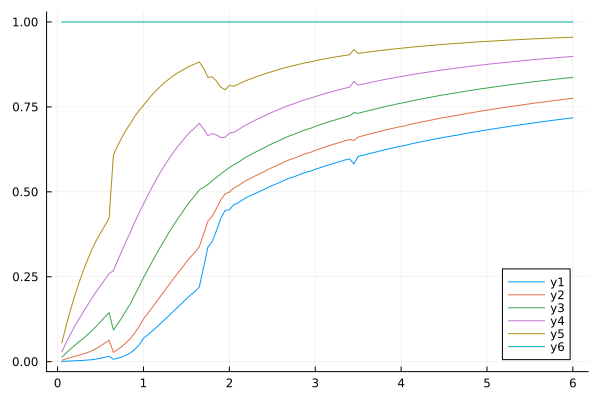

In [137]:
m = hcat([x.uB for x in results]...)
p = plot()
for i in 1:6
    plot!(p, d.alpha, vec(sum(m[1:i,:], dims= 1)))
end
display(p)

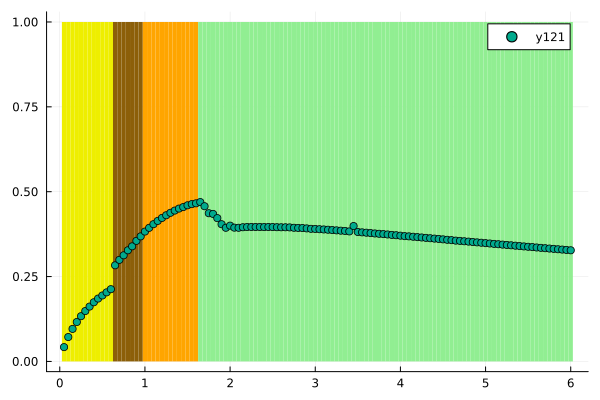

In [118]:
p = plot()
for row in eachrow(d)
    x1 = row["alpha"] - 0.025
    x2 = row["alpha"] + 0.025
    y1 = 0
    y2 = 1
    plot!(p, Shape([x1,x2,x2,x1],[y1,y1,y2,y2]), color=strategy_colors[row["strategy_theta"]],label="", linecolor=:transparent)
end
#scatter!(d.alpha, [x.meanA for x in results], color="#447821", label="good")
#scatter!(d.alpha, [(argmax(x.uB)-1)/5 for x in results])
colors = palette([:white,:black],6)
#for i in 1:6
#    scatter!(p, d.alpha, [x.uB[i] for x in results], color = colors[i])
#end
scatter!(p, d.alpha, [0.3*entropy(x.uA) for x in results])
display(p)
#scatter!(d.alpha, [x.meanB for x in results])
#scatter!(d.alpha, [x.uB[6] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.uB[5] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.uB[4] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.uB[3] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.uB[2] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.uB[1] for x in results], color="#447821", label="good", marker=:diamond)
#scatter!(d.alpha, [x.meanB for x in results], color="#C6E9AF", label="bad")
#scatter!(d.alpha, [x.uB[1] for x in results], color="#C6E9AF", label="bad", marker=:diamond)

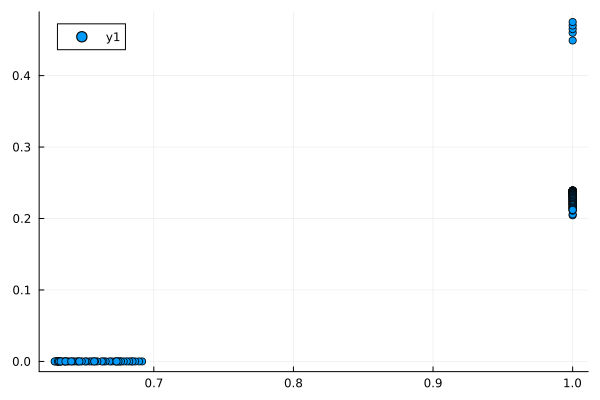

In [81]:
scatter(d.thetaAA,d.thetaBB)

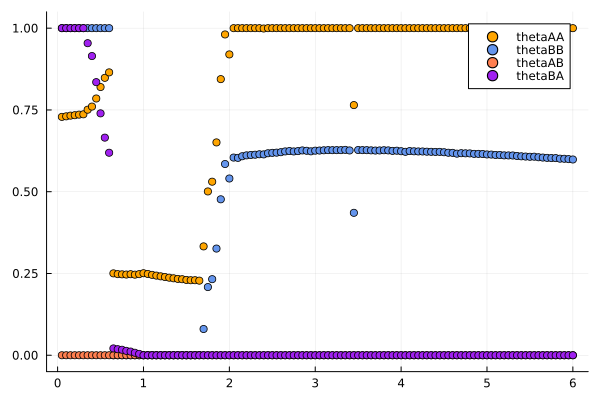

In [47]:
scatter(d.alpha, d.thetaAA, ylims=(-0.05,1.05), color="#FFA500", label="thetaAA")
scatter!(d.alpha, d.thetaBB, color="#6495ED", label="thetaBB")
scatter!(d.alpha, d.thetaAB, color="#FF7F50", label="thetaAB")
scatter!(d.alpha, d.thetaBA, color="#A020F0", label="thetaBA")